# Road Accident Severity Prediction — Arrival-Time Triage Support

**Predictive Care · Group 24 · CS3501 Data Science and Engineering Project**

---

## The question this answers

A nurse must judge, within minutes and before any workup, how much care a road-accident patient
needs.

> **Is this patient likely to need escalated care — transfer, a major procedure, or further
> interventions?**

The model replies with a flag, a probability against the average arrival, and a plain-language
reason — or says it cannot reliably tell.

---

## Design commitments

| Commitment | How it is enforced |
|---|---|
| Only arrival-time information | All 132 columns audited in Section 3 |
| An auditable severity label | An explicit clinical rule, not a cluster |
| Honest performance estimate | Three-way split; holdout opened once (Section 16) |
| Decisions derived, not assumed | Threshold, zones, floor all measured on validation |
| Explanations a nurse can read | Occlusion-based, plain language |

---

## Why the three-way split

Inspecting a test set repeatedly while a design changes is leakage through the analyst — the test
set stops being unseen. To avoid it: **train (60%)** fits models, **validation (20%)** drives
every decision, **holdout (20%)** opens once, in Section 16, after everything is frozen.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (ExtraTreesClassifier, HistGradientBoostingClassifier,
                              RandomForestClassifier)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, fbeta_score,
                             precision_recall_curve, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
DATA_PATH = "Preprocessed_Dataset.csv"
ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(exist_ok=True)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SEARCH_CV = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.random.seed(RANDOM_STATE)
print("Setup complete.")

Setup complete.


## 3. Leakage audit — the arrival-time contract

Any field the nurse could not know at arrival is unusable. Two failure modes are guarded against:
**post-treatment leakage** (known only after workup) and **practical unavailability** (scene
details that look safe but the nurse never had — road conditions, speed, blood alcohol).

| Class | Meaning |
|---|---|
| `ARRIVAL` | Usable |
| `SCENE_OR_TEST_DEPENDENT` | Scene reconstruction or lab-dependent |
| `POST_ARRIVAL` | Known only after workup/treatment |
| `TARGET_INPUT` | Defines the label, never a feature |
| `ADMIN` | Hospital/record identity |
| `EXCLUDED_ETHICAL` | Socioeconomic and sensitive attributes |
| `BOOKKEEPING` | Auto-generated `_missing_reason` columns |

An assertion enforces every column is classified.

In [2]:
df_raw = pd.read_csv(DATA_PATH)
print(f"Loaded {df_raw.shape[0]:,} patient records x {df_raw.shape[1]} columns")

df = df_raw.copy()
for c in df.columns:
    if df[c].dtype == object or str(df[c].dtype) == "str":
        df[c] = (df[c].astype(str).str.strip().str.lower()
                 .replace({"nan": np.nan, "none": np.nan, "": np.nan}))
print("Text columns normalised.")

Loaded 6,178 patient records x 130 columns
Text columns normalised.


## 4. Defining severity

Not recorded directly, so it is constructed from four candidate markers: discharge outcome,
transfer, major procedure, and length of stay. The fourth is tested first, since it looks like the
most natural severity signal and turns out to be misleading.

In [3]:
TARGET_INPUT = [
    "Discharge Outcome", "Transfer To Next Hospital", "Treatment During Tranfer",
    "State of Transfer", "Management Name 1", "Management Name 2",
    "Management Done At First Hospital", "Number of Wards Stayed",
    "Number of days in first ward", "Number of days in Second ward",
    "Number of days in Third ward", "Reason for stay in first ward",
    "Reason for stay in Second ward", "Reason for stay in Third ward",
]

POST_ARRIVAL = [
    "Investigation Done", "Type of injury No 1", "Type of Injury No 2", "Side", "Side.1",
    "Transport Time To Second Hospital", "Access To Wash Room",
    "Type of Toilet Modification", "Time between Alcohol Consumption and Accident",
]

SCENE_OR_TEST_DEPENDENT = [
    "Alcohol Consumption", "Illicit Drugs",
    "Engine Capacity",
    "Collision Force From", "Approximate Speed",
    "Category of Road", "Road Type", "Road Condition", "Visiblity", "Road Signals Exist",
]

ADMIN = ["Current Hospital Name", "First Hospital Name", "Incident At Time and Date",
         "Date Of Birth"]

EXCLUDED_ETHICAL = [
    "Bystander Expenditure per day", "Traveling Expenditure per day",
    "Total Traveling Expenditure For Whole Hospital Stay",
    "Family Monthly Income Before Accident", "Family Monthly Income After Accident",
    "Family Current Status", "Hospital Distance From Home", "Any Insurance Claim Type",
    "Any Other Hospital Admission Expenditure", "Vehicle Insured", "Vehicle Insurance Type",
    "Occupation", "Employment Type Name", "Educational Qualification", "Life Style",
    "Dress Name",
]

BOOKKEEPING = [c for c in df.columns if c.endswith("_missing_reason")]

_assigned = (set(TARGET_INPUT) | set(POST_ARRIVAL) | set(SCENE_OR_TEST_DEPENDENT) |
             set(ADMIN) | set(EXCLUDED_ETHICAL) | set(BOOKKEEPING))
ARRIVAL = [c for c in df.columns if c not in _assigned]

audit = pd.Series(
    {**{c: "TARGET_INPUT" for c in TARGET_INPUT},
     **{c: "POST_ARRIVAL" for c in POST_ARRIVAL},
     **{c: "SCENE_OR_TEST_DEPENDENT" for c in SCENE_OR_TEST_DEPENDENT},
     **{c: "ADMIN" for c in ADMIN},
     **{c: "EXCLUDED_ETHICAL" for c in EXCLUDED_ETHICAL},
     **{c: "BOOKKEEPING" for c in BOOKKEEPING},
     **{c: "ARRIVAL" for c in ARRIVAL}}
).reindex(df.columns)

assert audit.notna().all(), f"Unclassified: {list(audit[audit.isna()].index)}"
print(audit.value_counts().to_string())
print(f"\nAll {len(audit)} columns classified.\n")

print(f"Mean missingness, SCENE_OR_TEST_DEPENDENT: "
      f"{df[SCENE_OR_TEST_DEPENDENT].isna().mean().mean():.1%}")
print(f"Mean missingness, ARRIVAL:                 {df[ARRIVAL].isna().mean().mean():.1%}\n")

print("ARRIVAL-eligible columns:")
for c in ARRIVAL:
    print(f"   {c:42s} missing={df[c].isna().mean():5.1%}")

BOOKKEEPING                65
EXCLUDED_ETHICAL           16
TARGET_INPUT               14
ARRIVAL                    12
SCENE_OR_TEST_DEPENDENT    10
POST_ARRIVAL                9
ADMIN                       4

All 130 columns classified.

Mean missingness, SCENE_OR_TEST_DEPENDENT: 31.6%
Mean missingness, ARRIVAL:                 31.3%

ARRIVAL-eligible columns:
   Time of Collision                          missing=12.8%
   Age                                        missing=16.2%
   Mode Of Travel During Accident             missing= 9.3%
   Collision With                             missing=24.8%
   Vehicle Type                               missing=27.7%
   Helmet Worn                                missing=41.4%
   Passenger Type                             missing=96.2%
   Mode of Transport to the Hospital          missing=41.8%
   Time Taken To Reach Hospital               missing=23.2%
   Site of Injury No1                         missing= 8.6%
   Site of injury No 2             

### 4a. Length of stay runs backwards here

This is a peripheral hospital. A patient too badly injured to manage is sent elsewhere, so their
stay here is short — not because they were fine, but because they were too sick to keep. Treated
as a severity signal, it would score the most critical patients as low acuity. Tested next against
unambiguously life-threatening injuries.

In [4]:
ward_cols = ["Number of days in first ward", "Number of days in Second ward",
             "Number of days in Third ward"]
for c in ward_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
    early = df[f"{c}_missing_reason"] == "early_discharge"
    df.loc[early, c] = df.loc[early, c].fillna(0)
df["total_days"] = df[ward_cols].sum(axis=1, min_count=1)
print(f"total_days  median={df['total_days'].median():.0f}  max={df['total_days'].max():.0f}")

total_days  median=1  max=29


## 5. Independent validation of the label

$$\text{severity\_high} = \text{further interventions} \;\lor\; \text{transferred out}
\;\lor\; \text{major procedure}$$

Each disjunct traces to a recorded fact. **Caveat:** fracture stabilisation counts as a major
procedure, mechanically raising the rate for fracture patients — flagged in Section 5 below.

Built without injury type, so injury type is used here as an independent check.

Life-threatening injuries (n=133):

  transfer rate            22.6%  vs 11.6% overall
  share staying >= 3 days  11.3%  vs 18.3% overall


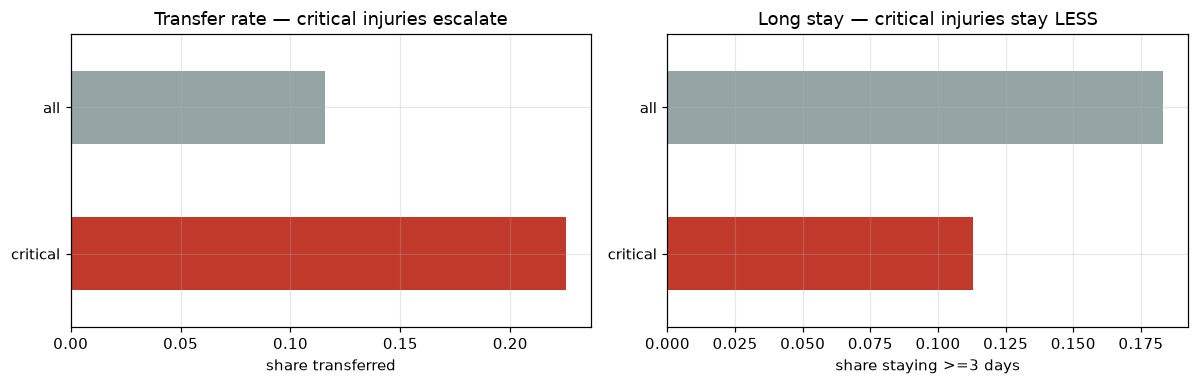


Critical patients escalate about twice as often, yet stay less. Length of stay measures
resource use at THIS hospital, not severity. It is EXCLUDED from the label.


In [5]:
transferred = df["Transfer To Next Hospital"].eq("yes")
CRITICAL_INJURY = {"spinal cord injury", "ich", "sdh", "pneumothorax", "pericardial effusion",
                   "kidney injury", "spleen injury", "bowel injury", "lung injury"}
is_critical = df["Type of injury No 1"].isin(CRITICAL_INJURY)

print(f"Life-threatening injuries (n={is_critical.sum()}):\n")
print(f"  transfer rate           {transferred[is_critical].mean():6.1%}  vs {transferred.mean():.1%} overall")
print(f"  share staying >= 3 days {df.loc[is_critical, 'total_days'].ge(3).mean():6.1%}  "
      f"vs {df['total_days'].ge(3).mean():.1%} overall")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
pd.Series({"critical": transferred[is_critical].mean(), "all": transferred.mean()}).plot(
    kind="barh", ax=ax[0], color=["#c0392b", "#95a5a6"])
ax[0].set(title="Transfer rate — critical injuries escalate", xlabel="share transferred")
pd.Series({"critical": df.loc[is_critical, "total_days"].ge(3).mean(),
           "all": df["total_days"].ge(3).mean()}).plot(
    kind="barh", ax=ax[1], color=["#c0392b", "#95a5a6"])
ax[1].set(title="Long stay — critical injuries stay LESS", xlabel="share staying >=3 days")
plt.tight_layout(); plt.savefig(ARTIFACTS / "confound.png", bbox_inches="tight"); plt.show()

print("\nCritical patients escalate about twice as often, yet stay less. Length of stay measures")
print("resource use at THIS hospital, not severity. It is EXCLUDED from the label.")

Laceration sits clearly lowest, dangerous groups sit above the overall rate.
Separation is moderate rather than dramatic: a peripheral hospital transfers its sickest patients
quickly, capping how sharply this facility's records can separate severity.

In [6]:
MAJOR_PROCEDURES = {"surgery", "fracture stabilization", "wound debridement",
                    "ligamental injury management"}

m_outcome  = df["Discharge Outcome"].eq("further interventions")
m_transfer = df["Transfer To Next Hospital"].eq("yes")
m_major    = (df["Management Name 1"].isin(MAJOR_PROCEDURES) |
              df["Management Name 2"].isin(MAJOR_PROCEDURES))
df["severity_high"] = (m_outcome | m_transfer | m_major).astype(int)

print(pd.DataFrame({
    "marker": ["further interventions", "transferred out", "major procedure"],
    "n": [m_outcome.sum(), m_transfer.sum(), m_major.sum()],
    "share": [m_outcome.mean(), m_transfer.mean(), m_major.mean()],
}).to_string(index=False, formatters={"share": "{:.1%}".format}))

print(f"\nHIGH severity: {df['severity_high'].sum():,} of {len(df):,} "
      f"({df['severity_high'].mean():.1%})")
print(f"Label-defining fields missing for any patient: "
      f"{int((m_outcome.isna() | m_transfer.isna()).sum())}")

               marker   n share
further interventions 318  5.1%
      transferred out 715 11.6%
      major procedure 756 12.2%

HIGH severity: 1,505 of 6,178 (24.4%)
Label-defining fields missing for any patient: 0


## 6. Feature engineering

Eight features derived from arrival-time fields using trauma-care reasoning.

| Feature | Rationale |
|---|---|
| `injury_region_1/2` | 43 raw sites collapse to anatomical regions |
| `torso_head_injury` | Head/spine/chest/abdomen/pelvis carry far higher risk than limbs |
| `multiple_injury_sites` | More than one injured region suggests higher energy transfer |
| `night_collision` | Poorer visibility, slower response |
| `vulnerable_road_user` | No vehicle structure absorbs impact |
| `heavy_counterpart` | A heavier counterpart transfers more energy |
| `ambulance_arrival` | Proxies a bystander's judgement at the scene |

               injury group    n HIGH severity rate
                 fracture * 1444              40.2%
                  contusion  285              38.2%
critical (organ/spine/head)  133              30.1%
                 amputation  137              27.0%
               nerve lesion  269              25.3%
                   abrasion  670              24.8%
            ligament injury  170              21.8%
                dislocation  143              17.5%
                 laceration 2147              15.9%

* fracture is favoured by construction. Overall rate: 24.4%


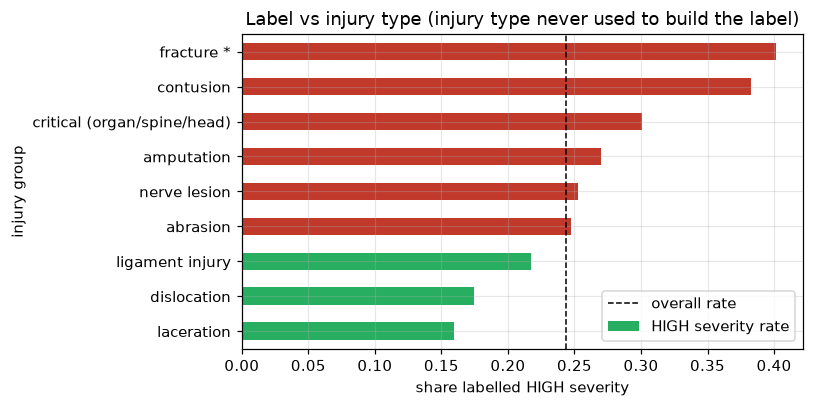

In [7]:
injury = df["Type of injury No 1"]
groups = {
    "critical (organ/spine/head)": injury.isin(CRITICAL_INJURY),
    "amputation": injury.eq("amputation"), "fracture *": injury.eq("fracture"),
    "nerve lesion": injury.eq("nerve lesion"), "dislocation": injury.eq("dislocation"),
    "ligament injury": injury.eq("ligament injury"), "contusion": injury.eq("contusion"),
    "abrasion": injury.eq("abration"), "laceration": injury.eq("laceration"),
}
val = pd.DataFrame([{"injury group": g, "n": int(m.sum()),
                     "HIGH severity rate": df.loc[m, "severity_high"].mean()}
                    for g, m in groups.items() if m.sum() >= 30]
                   ).sort_values("HIGH severity rate", ascending=False)
print(val.to_string(index=False, formatters={"HIGH severity rate": "{:.1%}".format}))
print(f"\n* fracture is favoured by construction. Overall rate: {df['severity_high'].mean():.1%}")

plt.figure(figsize=(7.5, 3.8))
v = val.set_index("injury group")["HIGH severity rate"].sort_values()
v.plot(kind="barh", color=["#27ae60" if x < df["severity_high"].mean() else "#c0392b" for x in v])
plt.axvline(df["severity_high"].mean(), color="k", ls="--", lw=1, label="overall rate")
plt.xlabel("share labelled HIGH severity"); plt.legend()
plt.title("Label vs injury type (injury type never used to build the label)")
plt.tight_layout(); plt.savefig(ARTIFACTS / "label_validation.png", bbox_inches="tight"); plt.show()

Engineering is a single function, used in training and at prediction time alike —
no separate copy to drift out of sync. Missingness propagates: `isin_or_nan()` keeps a missing
source missing rather than silently returning False.

## 7. Three-way split

The split happens now, before any target-involving analysis.

- **Train (60%)** — models fitted here
- **Validation (20%)** — every decision made here: feature set, model, hyperparameters,
  threshold, zones, completeness floor
- **Holdout (20%)** — untouched until Section 16

Stratified, so all three carry the same severity rate.

In [8]:
def to_region(site):
    """Collapse raw injury sites into anatomical regions."""
    if pd.isna(site):
        return np.nan
    if "no injury" in site or "no secondary" in site:
        return "none"
    if any(k in site for k in ["head", "forehead", "facial", "eye"]):
        return "head_face"
    if any(k in site for k in ["cervical", "thoracic", "lumbar", "sacrum"]):
        return "spine"
    if "chest" in site:
        return "chest"
    if "abdomen" in site:
        return "abdomen"
    if "pelvis" in site:
        return "pelvis"
    if any(k in site for k in ["shoulder", "clavicle", "humerus", "elbow", "forearm",
                               "hand", "carpal"]):
        return "upper_limb"
    if any(k in site for k in ["thigh", "femur", "knee", "leg", "foot", "tarsal",
                               "patella", "fibula", "tibia"]):
        return "lower_limb"
    return "other"


HIGH_RISK_REGIONS = {"head_face", "spine", "chest", "abdomen", "pelvis"}
NIGHT_WINDOWS     = {"21:00 - 00:00", "00:00 - 03:00", "03:00 - 06:00"}
VULNERABLE_USERS  = {"motor cyclist", "motorbike pillion rider", "bicycle",
                     "bicycle pillion", "pedestrian"}
HEAVY_COUNTERPART = {"heavy vehicle", "car or van", "three wheeler", "bus", "train"}

ENGINEERED_SOURCES = {
    "injury_region_1":       ["Site of Injury No1"],
    "injury_region_2":       ["Site of injury No 2"],
    "torso_head_injury":     ["Site of Injury No1", "Site of injury No 2"],
    "multiple_injury_sites": ["Site of injury No 2"],
    "night_collision":       ["Time of Collision"],
    "vulnerable_road_user":  ["Mode Of Travel During Accident"],
    "heavy_counterpart":     ["Collision With "],
    "ambulance_arrival":     ["Mode of Transport to the Hospital"],
}
ENGINEERED = list(ENGINEERED_SOURCES)

ORDINAL_ORDERS = {
    "Age": ["1-9", "10-19", "20-29", "30-39", "40-49", "50-59",
            "60-69", "70-79", "80-89", "90-100"],
    "Time Taken To Reach Hospital": ["less than 15 minutes", "15 minutes - 30 minutes",
                                     "30 minutes - 1 hour", "1 hour - 2 hour",
                                     "more than 2 hour"],
}


def isin_or_nan(series, values):
    """Like .isin(), but keeps missing values missing instead of returning False."""
    return series.map(lambda v: np.nan if pd.isna(v) else (v in values))


def engineer_features(frame):
    """Derive engineered features. Used on full data and on single records alike."""
    out = frame.copy()
    have = lambda cols: all(c in out.columns for c in cols)

    if have(["Site of Injury No1"]):
        out["injury_region_1"] = out["Site of Injury No1"].map(to_region)
    if have(["Site of injury No 2"]):
        out["injury_region_2"] = out["Site of injury No 2"].map(to_region)
    if have(["Site of Injury No1", "Site of injury No 2"]):
        out["torso_head_injury"] = np.where(
            out["injury_region_1"].isna() & out["injury_region_2"].isna(), np.nan,
            (out["injury_region_1"].isin(HIGH_RISK_REGIONS) |
             out["injury_region_2"].isin(HIGH_RISK_REGIONS)).astype(float))
    if have(["Site of injury No 2"]):
        out["multiple_injury_sites"] = np.where(
            out["injury_region_2"].isna(), np.nan,
            (~out["injury_region_2"].eq("none")).astype(float))
    if have(["Time of Collision"]):
        out["night_collision"] = isin_or_nan(out["Time of Collision"], NIGHT_WINDOWS).astype(float)
    if have(["Mode Of Travel During Accident"]):
        out["vulnerable_road_user"] = isin_or_nan(
            out["Mode Of Travel During Accident"], VULNERABLE_USERS).astype(float)
    if have(["Collision With "]):
        out["heavy_counterpart"] = isin_or_nan(
            out["Collision With "], HEAVY_COUNTERPART).astype(float)
    if have(["Mode of Transport to the Hospital"]):
        out["ambulance_arrival"] = np.where(
            out["Mode of Transport to the Hospital"].isna(), np.nan,
            out["Mode of Transport to the Hospital"].eq("ambulance").astype(float))
    return out


def apply_ordinal_encoding(frame):
    """Map ordered text bands to integers."""
    out = frame.copy()
    for col, order in ORDINAL_ORDERS.items():
        if col in out.columns:
            out[col] = out[col].map({v: i for i, v in enumerate(order)})
    return out


df = engineer_features(df)
CANDIDATES = ARRIVAL + ENGINEERED
X_all = apply_ordinal_encoding(df[CANDIDATES])
y_all = df["severity_high"].copy()

CAT_COLS = [c for c in X_all.columns
            if X_all[c].dtype == object or str(X_all[c].dtype) == "str"]
NUM_COLS = [c for c in X_all.columns if c not in CAT_COLS]
print(f"{len(CANDIDATES)} candidates ({len(ARRIVAL)} raw + {len(ENGINEERED)} engineered)")
print(f"  categorical {len(CAT_COLS)}   numeric/ordinal {len(NUM_COLS)}")

20 candidates (12 raw + 8 engineered)
  categorical 12   numeric/ordinal 8


## 8. Exploratory checks — training data only

Missingness is heavy and **informative rather than random**: `Helmet Worn` is blank for patients
not on a motorbike, not because the nurse forgot. Left missing and handled natively rather than
imputed away.

In [9]:
X_dev, X_hold, y_dev, y_hold = train_test_split(
    X_all, y_all, test_size=0.20, stratify=y_all, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=RANDOM_STATE)

for name, y_part in [("Train", y_train), ("Validation", y_val), ("Holdout", y_hold)]:
    print(f"{name:12s} {len(y_part):5,} rows   severity {y_part.mean():.1%}")
print("\nHoldout is not read again until Section 16.")

Train        3,706 rows   severity 24.4%
Validation   1,236 rows   severity 24.4%
Holdout      1,236 rows   severity 24.4%

Holdout is not read again until Section 16.


## 9. Feature selection

**Screening (diagnostic).** Chi-squared + Cramér's V for categoricals, Mann–Whitney U for
ordinals. **Decision by measured performance.** Three candidate sets fitted on train, scored on
validation; the winner is used, overriding screening where they disagree.

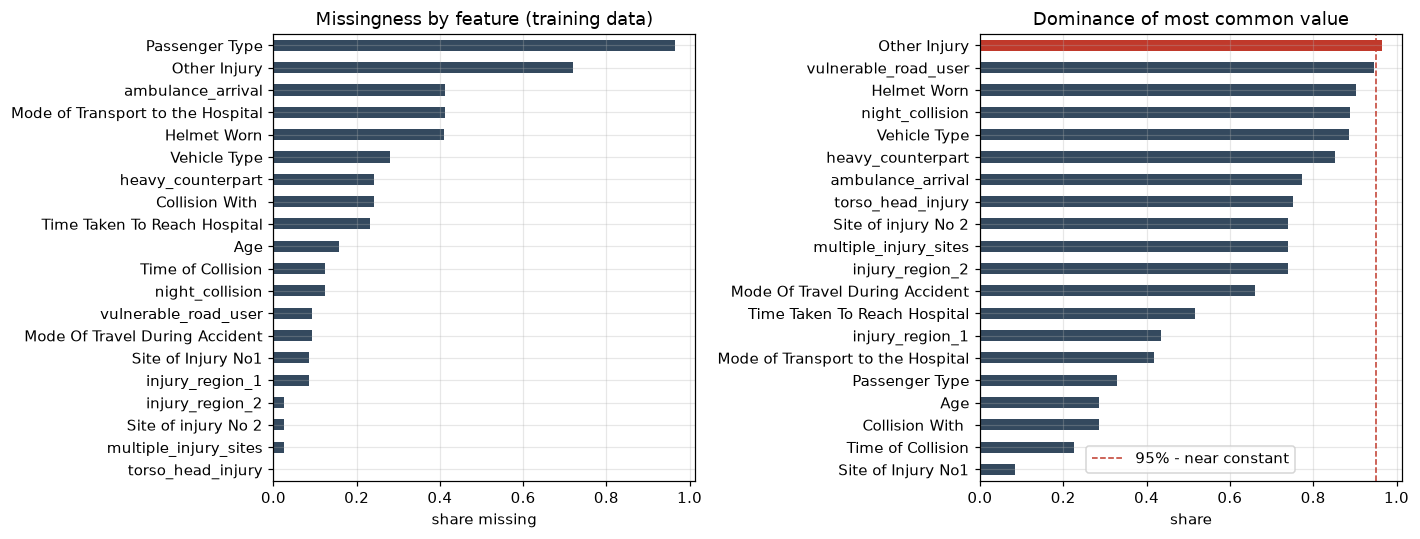

Near-constant features: ['Other Injury']


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
X_train.isna().mean().sort_values().plot(kind="barh", ax=axes[0], color="#34495e")
axes[0].set(title="Missingness by feature (training data)", xlabel="share missing")

dominance = pd.Series({c: X_train[c].value_counts(normalize=True, dropna=True).iloc[0]
                       for c in X_train.columns if X_train[c].notna().any()}).sort_values()
dominance.plot(kind="barh", ax=axes[1],
               color=["#c0392b" if v >= 0.95 else "#34495e" for v in dominance])
axes[1].axvline(0.95, color="#c0392b", ls="--", lw=1, label="95% - near constant")
axes[1].set(title="Dominance of most common value", xlabel="share"); axes[1].legend()
plt.tight_layout(); plt.savefig(ARTIFACTS / "eda.png", bbox_inches="tight"); plt.show()

near_constant = [c for c, v in dominance.items() if v >= 0.95]
print(f"Near-constant features: {near_constant if near_constant else 'none'}")

## 10. Model comparison

Five candidates plus a stratified dummy, fitted on train, scored on validation.

**Metrics.** Accuracy is meaningless at ~24% prevalence. Instead: **PR-AUC** (primary), **ROC-AUC**
for ranking, **F2** (recall-weighted), **Brier** for probability quality.

Imbalance handled by class weighting, not SMOTE — interpolating categorical crash records would
fabricate impossible combinations.

In [11]:
screen_rows = []
for col in CAT_COLS:
    ct = pd.crosstab(X_train[col], y_train)
    if ct.shape[0] < 2:
        continue
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    screen_rows.append({"feature": col, "test": "chi2", "p_value": p, "effect_size": v,
                        "keep": bool(p <= 0.05 and v >= 0.05)})
for col in NUM_COLS:
    a, b = X_train.loc[y_train == 1, col].dropna(), X_train.loc[y_train == 0, col].dropna()
    if len(a) < 10 or len(b) < 10:
        continue
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    screen_rows.append({"feature": col, "test": "mannwhitney", "p_value": p,
                        "effect_size": abs(2 * u / (len(a) * len(b)) - 1),
                        "keep": bool(p <= 0.05)})

screening = pd.DataFrame(screen_rows).sort_values("effect_size", ascending=False)
print(screening.to_string(index=False, formatters={"p_value": "{:.3g}".format,
                                                   "effect_size": "{:.3f}".format}))


def build_preprocessor(cols):
    cats = [c for c in cols if c in CAT_COLS]
    nums = [c for c in cols if c not in cats]
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), nums),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                          ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                   min_frequency=20))]), cats),
    ])


REFERENCE_MODEL = RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
    random_state=RANDOM_STATE, n_jobs=-1)

strict = [c for c in X_all.columns if c in set(screening.loc[screening["keep"], "feature"])]
relaxed = [c for c in X_all.columns
           if c in set(screening.loc[screening["p_value"] <= 0.05, "feature"])]
everything = list(X_all.columns)

selection = []
for name, cols in [("strict (p and effect size)", strict), ("relaxed (p only)", relaxed),
                   ("all candidates", everything)]:
    pipe = Pipeline([("pre", build_preprocessor(cols)), ("clf", REFERENCE_MODEL)])
    pipe.fit(X_train[cols], y_train)
    score = average_precision_score(y_val, pipe.predict_proba(X_val[cols])[:, 1])
    selection.append({"feature set": name, "n_features": len(cols), "val_PR_AUC": score})

selection = pd.DataFrame(selection).sort_values("val_PR_AUC", ascending=False).reset_index(drop=True)
print("\nFeature-set comparison (fitted on train, scored on validation):")
print(selection.to_string(index=False, float_format="%.4f"))

winner = selection.loc[0, "feature set"]
FEATURES = {"strict (p and effect size)": strict, "relaxed (p only)": relaxed,
            "all candidates": everything}[winner]
DROPPED = [c for c in X_all.columns if c not in FEATURES]
CAT_FEATURES = [c for c in FEATURES if c in CAT_COLS]
NUM_FEATURES = [c for c in FEATURES if c in NUM_COLS]

X_train, X_val, X_hold = X_train[FEATURES], X_val[FEATURES], X_hold[FEATURES]
print(f"\nSelected '{winner}' -> {len(FEATURES)} features, {len(DROPPED)} dropped")
print(f"Dropped: {DROPPED}")

                          feature        test  p_value effect_size  keep
               Site of Injury No1        chi2 1.68e-29       0.265  True
                   Passenger Type        chi2    0.253       0.204 False
              Site of injury No 2        chi2 6.81e-06       0.162  True
Mode of Transport to the Hospital        chi2 1.23e-05       0.108  True
                  Collision With         chi2   0.0012       0.105  True
     Time Taken To Reach Hospital mannwhitney 2.94e-06       0.105  True
                  injury_region_2        chi2  3.2e-06       0.102  True
                              Age mannwhitney 0.000185       0.086  True
            multiple_injury_sites mannwhitney 6.92e-07       0.085  True
   Mode Of Travel During Accident        chi2   0.0133       0.082  True
                Time of Collision        chi2    0.123       0.059 False
                torso_head_injury mannwhitney 0.000497       0.058  True
                ambulance_arrival mannwhitney   0.0

Every real model beats the dummy decisively and clusters tightly. When five
families agree this closely, the limit is the **information content of arrival-time data**, not
the algorithm.

In [12]:
preprocessor = build_preprocessor(FEATURES)


def as_categorical(frame):
    out = frame.copy()
    for c in CAT_FEATURES:
        out[c] = out[c].astype("category")
    return out


CANDIDATE_MODELS = {
    "Dummy (stratified)": (DummyClassifier(strategy="stratified", random_state=RANDOM_STATE), False),
    "Logistic Regression": (Pipeline([("pre", preprocessor),
        ("clf", LogisticRegression(max_iter=3000, class_weight="balanced",
                                   random_state=RANDOM_STATE))]), False),
    "Random Forest": (Pipeline([("pre", preprocessor),
        ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
                                       class_weight="balanced_subsample",
                                       random_state=RANDOM_STATE, n_jobs=-1))]), False),
    "Extra Trees": (Pipeline([("pre", preprocessor),
        ("clf", ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5,
                                     class_weight="balanced",
                                     random_state=RANDOM_STATE, n_jobs=-1))]), False),
    "HistGradientBoosting": (HistGradientBoostingClassifier(
        categorical_features="from_dtype", class_weight="balanced",
        random_state=RANDOM_STATE), True),
}

comparison, val_probs = [], {}
for name, (model, needs_cat) in CANDIDATE_MODELS.items():
    tr = as_categorical(X_train) if needs_cat else X_train
    va = as_categorical(X_val) if needs_cat else X_val
    model.fit(tr, y_train)
    p = model.predict_proba(va)[:, 1]
    val_probs[name] = p
    comparison.append({"model": name,
                       "PR_AUC": average_precision_score(y_val, p),
                       "ROC_AUC": roc_auc_score(y_val, p),
                       "F2@0.5": fbeta_score(y_val, (p >= 0.5).astype(int), beta=2),
                       "Brier": brier_score_loss(y_val, p)})

results = pd.DataFrame(comparison).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
print(results.to_string(index=False, float_format="%.4f"))
print(f"\nPR-AUC floor (prevalence) = {y_val.mean():.4f}")
BEST_MODEL = results.loc[0, "model"]
print(f"Selected for tuning: {BEST_MODEL}")

               model  PR_AUC  ROC_AUC  F2@0.5  Brier
         Extra Trees  0.4576   0.7150  0.5646 0.2032
       Random Forest  0.4552   0.7203  0.5451 0.1972
HistGradientBoosting  0.4184   0.6947  0.4780 0.1962
 Logistic Regression  0.4181   0.6965  0.5530 0.2216
  Dummy (stratified)  0.2397   0.4890  0.2315 0.3794

PR-AUC floor (prevalence) = 0.2435
Selected for tuning: Extra Trees


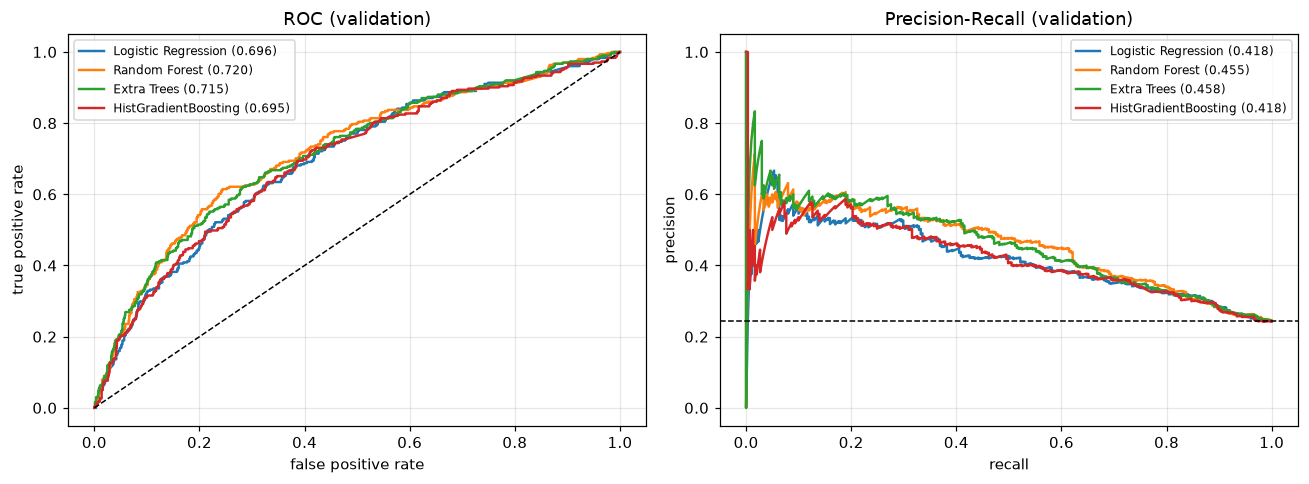

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, p in val_probs.items():
    if name.startswith("Dummy"):
        continue
    fpr, tpr, _ = roc_curve(y_val, p)
    axes[0].plot(fpr, tpr, lw=1.6, label=f"{name} ({roc_auc_score(y_val, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_val, p)
    axes[1].plot(rec, prec, lw=1.6, label=f"{name} ({average_precision_score(y_val, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC (validation)")
axes[1].axhline(y_val.mean(), color="k", ls="--", lw=1)
axes[1].set(xlabel="recall", ylabel="precision", title="Precision-Recall (validation)")
for a in axes:
    a.legend(fontsize=8)
plt.tight_layout(); plt.savefig(ARTIFACTS / "model_comparison.png", bbox_inches="tight"); plt.show()

## 11. Hyperparameter tuning

Randomised search, 25 configurations, 3-fold CV **inside training**. Random search over grid
search: explores more distinct values per parameter for the same budget. Validation confirms
afterwards, not used for fitting.

## 12. Probability calibration

A nurse reading "38% likely" needs that number to mean what it says. Tree ensembles push
probabilities toward the middle, so isotonic regression is fitted on train and kept **only if it
measurably improves Brier on validation**.

In [14]:
TUNING_GRIDS = {
    "Random Forest": (Pipeline([("pre", preprocessor),
        ("clf", RandomForestClassifier(class_weight="balanced_subsample",
                                       random_state=RANDOM_STATE, n_jobs=-1))]),
        {"clf__n_estimators": [200, 300, 400], "clf__max_depth": [None, 8, 12, 16],
         "clf__min_samples_leaf": [2, 5, 10, 20],
         "clf__max_features": ["sqrt", "log2", 0.3, 0.5]}, False),
    "Extra Trees": (Pipeline([("pre", preprocessor),
        ("clf", ExtraTreesClassifier(class_weight="balanced",
                                     random_state=RANDOM_STATE, n_jobs=-1))]),
        {"clf__n_estimators": [200, 300, 400], "clf__max_depth": [None, 8, 12, 16],
         "clf__min_samples_leaf": [2, 5, 10, 20],
         "clf__max_features": ["sqrt", "log2", 0.3, 0.5]}, False),
    "HistGradientBoosting": (HistGradientBoostingClassifier(
        categorical_features="from_dtype", class_weight="balanced", random_state=RANDOM_STATE),
        {"learning_rate": [0.02, 0.05, 0.1], "max_leaf_nodes": [7, 15, 31],
         "min_samples_leaf": [10, 20, 40], "l2_regularization": [0.0, 0.1, 1.0],
         "max_iter": [200, 400]}, True),
    "Logistic Regression": (Pipeline([("pre", preprocessor),
        ("clf", LogisticRegression(max_iter=5000, class_weight="balanced",
                                   random_state=RANDOM_STATE))]),
        {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10]}, False),
}

base_model, grid, NEEDS_CATEGORICAL = TUNING_GRIDS[BEST_MODEL]
train_data = as_categorical(X_train) if NEEDS_CATEGORICAL else X_train
val_data   = as_categorical(X_val) if NEEDS_CATEGORICAL else X_val

search = RandomizedSearchCV(base_model, grid, n_iter=25, scoring="average_precision",
                            cv=SEARCH_CV, random_state=RANDOM_STATE, n_jobs=-1, refit=True)
search.fit(train_data, y_train)
tuned_model = search.best_estimator_

print(f"Best inner-CV PR-AUC: {search.best_score_:.4f}")
for k, v in search.best_params_.items():
    print(f"   {k} = {v}")
print(f"\nTuned model on validation: "
      f"PR-AUC {average_precision_score(y_val, tuned_model.predict_proba(val_data)[:, 1]):.4f}")

Best inner-CV PR-AUC: 0.4061
   clf__n_estimators = 200
   clf__min_samples_leaf = 20
   clf__max_features = 0.3
   clf__max_depth = 16

Tuned model on validation: PR-AUC 0.4292


## 13. Decision threshold

A 0.5 cutoff assumes a miss and a false alarm cost the same — they don't. Rests on one stated
assumption:

> Missing a patient who needed escalation is `MISS_COST_RATIO` times worse than a false alarm.

The threshold minimises expected cost under that assumption. Sensitivity table shows other ratios
so a department can substitute its own. All computed on **validation**.

Brier  uncalibrated 0.2144   isotonic 0.1666
Decision: USE isotonic calibration


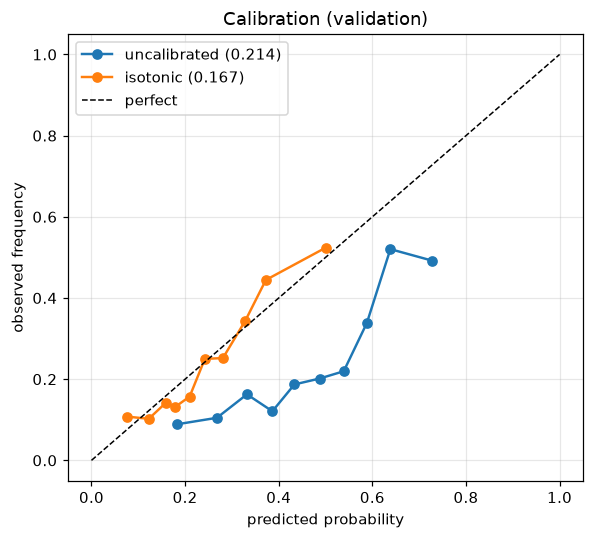

In [15]:
calibrated_model = CalibratedClassifierCV(tuned_model, method="isotonic", cv=SEARCH_CV)
calibrated_model.fit(train_data, y_train)

p_val_uncal = tuned_model.predict_proba(val_data)[:, 1]
p_val_cal   = calibrated_model.predict_proba(val_data)[:, 1]
brier_uncal, brier_cal = brier_score_loss(y_val, p_val_uncal), brier_score_loss(y_val, p_val_cal)
USE_CALIBRATION = brier_cal < brier_uncal

print(f"Brier  uncalibrated {brier_uncal:.4f}   isotonic {brier_cal:.4f}")
print(f"Decision: {'USE isotonic calibration' if USE_CALIBRATION else 'KEEP raw probabilities'}")

final_model = calibrated_model if USE_CALIBRATION else tuned_model
p_val = p_val_cal if USE_CALIBRATION else p_val_uncal

plt.figure(figsize=(5.5, 5))
for p, lab in [(p_val_uncal, f"uncalibrated ({brier_uncal:.3f})"),
               (p_val_cal, f"isotonic ({brier_cal:.3f})")]:
    true_frac, pred_frac = calibration_curve(y_val, p, n_bins=10, strategy="quantile")
    plt.plot(pred_frac, true_frac, "o-", lw=1.6, label=lab)
plt.plot([0, 1], [0, 1], "k--", lw=1, label="perfect")
plt.xlabel("predicted probability"); plt.ylabel("observed frequency")
plt.title("Calibration (validation)"); plt.legend()
plt.tight_layout(); plt.savefig(ARTIFACTS / "calibration.png", bbox_inches="tight"); plt.show()

## 14. Confidence zones

A fixed ±0.10 margin was tested and rejected: accuracy inside it was 48–58% and **fell as the band
widened**. Distance from a threshold is not a reliability signal.

Two cut points chosen on validation against stated requirements:

- **LOW** — observed severity ≤ `LOW_ZONE_MAX_SEVERITY`
- **HIGH** — observed severity ≥ `HIGH_ZONE_MIN_SEVERITY`
- **BORDERLINE** — everything between

Cut points maximise decided patients while both requirements hold.

 miss_cost_ratio  threshold  recall  specificity  alert_rate
               2      0.310   0.518        0.793       0.283
               3      0.250   0.664        0.665       0.415
               5      0.220   0.738        0.567       0.507
               8      0.150   0.904        0.277       0.767
              10      0.050   0.990        0.032       0.973
              15      0.050   0.990        0.032       0.973

Using MISS_COST_RATIO = 5  ->  threshold 0.22


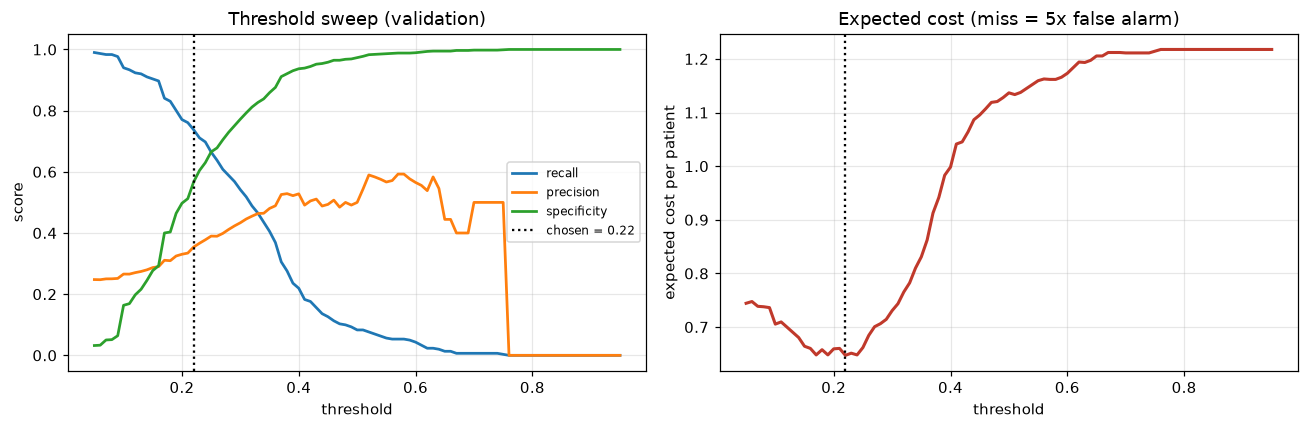

In [16]:
MISS_COST_RATIO = 5

sweep = []
for t in np.arange(0.05, 0.96, 0.01):
    pred = (p_val >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, pred, labels=[0, 1]).ravel()
    sweep.append({"threshold": t,
                  "recall": recall_score(y_val, pred, zero_division=0),
                  "precision": precision_score(y_val, pred, zero_division=0),
                  "specificity": recall_score(y_val, pred, pos_label=0, zero_division=0),
                  "alert_rate": pred.mean(),
                  "expected_cost": (MISS_COST_RATIO * fn + fp) / len(y_val)})
sweep = pd.DataFrame(sweep)
THRESHOLD = float(sweep.loc[sweep["expected_cost"].idxmin(), "threshold"])

sensitivity = []
for ratio in [2, 3, 5, 8, 10, 15]:
    costs = []
    for t in sweep["threshold"]:
        tn, fp, fn, tp = confusion_matrix(y_val, (p_val >= t).astype(int), labels=[0, 1]).ravel()
        costs.append(ratio * fn + fp)
    row = sweep.iloc[int(np.argmin(costs))]
    sensitivity.append({"miss_cost_ratio": ratio, "threshold": row["threshold"],
                        "recall": row["recall"], "specificity": row["specificity"],
                        "alert_rate": row["alert_rate"]})
print(pd.DataFrame(sensitivity).to_string(index=False, float_format="%.3f"))
print(f"\nUsing MISS_COST_RATIO = {MISS_COST_RATIO}  ->  threshold {THRESHOLD:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for col in ["recall", "precision", "specificity"]:
    axes[0].plot(sweep["threshold"], sweep[col], lw=1.8, label=col)
axes[0].axvline(THRESHOLD, color="k", ls=":", lw=1.5, label=f"chosen = {THRESHOLD:.2f}")
axes[0].set(xlabel="threshold", ylabel="score", title="Threshold sweep (validation)")
axes[0].legend(fontsize=8)
axes[1].plot(sweep["threshold"], sweep["expected_cost"], lw=2, color="#c0392b")
axes[1].axvline(THRESHOLD, color="k", ls=":", lw=1.5)
axes[1].set(xlabel="threshold", ylabel="expected cost per patient",
            title=f"Expected cost (miss = {MISS_COST_RATIO}x false alarm)")
plt.tight_layout(); plt.savefig(ARTIFACTS / "threshold_sweep.png", bbox_inches="tight"); plt.show()

## 15. Completeness floor

The model should refuse when it has too little to work with. Measured, not hand-set.

Discrimination is evaluated per completeness level on validation; the floor is the lowest level
where the model still ranks patients usefully.

**ROC-AUC, not PR-AUC** — PR-AUC moves with prevalence, which differs across completeness levels,
so those comparisons would not be like-for-like. ROC-AUC is prevalence-independent.

 low_cut  high_cut  low_severity  high_severity  decided
   0.080     0.320         0.094          0.455    0.304
   0.070     0.320         0.096          0.455    0.303
   0.080     0.330         0.094          0.464    0.287
   0.070     0.330         0.096          0.464    0.286
   0.080     0.340         0.094          0.465    0.271

LOW  zone: p <  0.08   observed severity 9.4%
HIGH zone: p >= 0.32   observed severity 45.5%
Decided (not borderline): 30.4% of validation patients


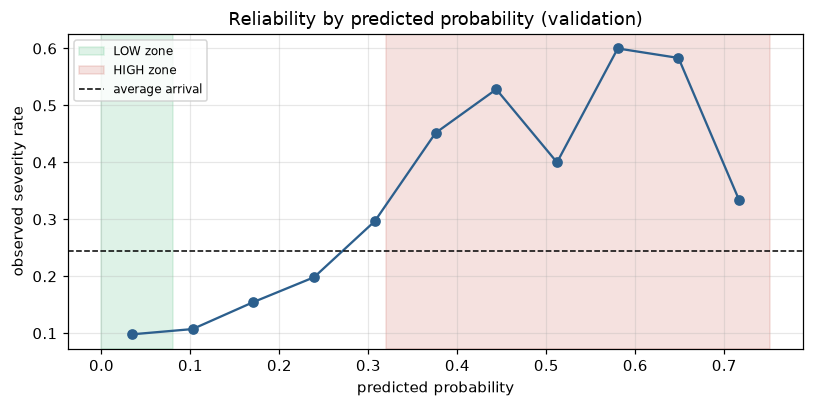

In [17]:
LOW_ZONE_MAX_SEVERITY  = 0.10
HIGH_ZONE_MIN_SEVERITY = 0.45

zone_rows = []
for lo in np.arange(0.05, 0.26, 0.01):
    for hi in np.arange(0.25, 0.71, 0.01):
        if hi <= lo:
            continue
        in_low, in_high = p_val < lo, p_val >= hi
        if in_low.sum() < 40 or in_high.sum() < 40:
            continue
        low_rate, high_rate = y_val[in_low].mean(), y_val[in_high].mean()
        if low_rate <= LOW_ZONE_MAX_SEVERITY and high_rate >= HIGH_ZONE_MIN_SEVERITY:
            zone_rows.append({"low_cut": lo, "high_cut": hi, "low_severity": low_rate,
                              "high_severity": high_rate,
                              "decided": in_low.mean() + in_high.mean()})

zones = pd.DataFrame(zone_rows)
if zones.empty:
    LOW_CUT = HIGH_CUT = THRESHOLD
    print("No cut points met both requirements - every prediction would be BORDERLINE.")
else:
    best = zones.loc[zones["decided"].idxmax()]
    LOW_CUT, HIGH_CUT = float(best["low_cut"]), float(best["high_cut"])
    print(zones.nlargest(5, "decided").to_string(index=False, float_format="%.3f"))
    print(f"\nLOW  zone: p <  {LOW_CUT:.2f}   observed severity {best['low_severity']:.1%}")
    print(f"HIGH zone: p >= {HIGH_CUT:.2f}   observed severity {best['high_severity']:.1%}")
    print(f"Decided (not borderline): {best['decided']:.1%} of validation patients")

plt.figure(figsize=(7.5, 3.8))
bins = np.linspace(0, p_val.max(), 12)
centres = (bins[:-1] + bins[1:]) / 2
rates = [y_val[(p_val >= a) & (p_val < b)].mean() for a, b in zip(bins[:-1], bins[1:])]
plt.plot(centres, rates, "o-", color="#2c5f8d")
plt.axvspan(0, LOW_CUT, color="#27ae60", alpha=0.15, label="LOW zone")
plt.axvspan(HIGH_CUT, bins[-1], color="#c0392b", alpha=0.15, label="HIGH zone")
plt.axhline(y_val.mean(), color="k", ls="--", lw=1, label="average arrival")
plt.xlabel("predicted probability"); plt.ylabel("observed severity rate")
plt.title("Reliability by predicted probability (validation)"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(ARTIFACTS / "confidence_zones.png", bbox_inches="tight"); plt.show()

## 16. Held-out evaluation — opened once

Everything is frozen: features, model, hyperparameters, calibration, threshold, zones, and
completeness floor were all chosen on train and validation. Read here for the first and only
time. Nothing below is re-tuned in response to what it shows.

In [18]:
MIN_USABLE_AUC = 0.60

RAW_INPUTS = []
for f in FEATURES:
    for src in ENGINEERED_SOURCES.get(f, [f]):
        if src not in RAW_INPUTS:
            RAW_INPUTS.append(src)

raw_val = df.loc[X_val.index, RAW_INPUTS]
completeness_val = raw_val.notna().sum(axis=1) / len(RAW_INPUTS)

floor_rows = []
for level in sorted(completeness_val.unique()):
    at_level = completeness_val == level
    if at_level.sum() < 30 or y_val[at_level].nunique() < 2:
        continue
    floor_rows.append({"completeness": level, "patients": int(at_level.sum()),
                       "severity_rate": y_val[at_level].mean(),
                       "ROC_AUC": roc_auc_score(y_val[at_level], p_val[at_level])})

floors = pd.DataFrame(floor_rows).sort_values("completeness")
floors["usable"] = floors["ROC_AUC"] >= MIN_USABLE_AUC
print(floors.to_string(index=False, float_format="%.3f"))

usable = floors.loc[floors["usable"], "completeness"]
COMPLETENESS_FLOOR = float(usable.min()) if not usable.empty else 0.0
print(f"\nFloor: {COMPLETENESS_FLOOR:.2f} "
      f"({int(np.ceil(COMPLETENESS_FLOOR * len(RAW_INPUTS)))} of {len(RAW_INPUTS)} fields) "
      f"-> defers {(completeness_val < COMPLETENESS_FLOOR).mean():.1%} of validation records")

 completeness  patients  severity_rate  ROC_AUC  usable
        0.083        42          0.119    0.500   False
        0.167        34          0.088    0.742    True
        0.417        55          0.091    0.618    True
        0.500        77          0.195    0.585   False
        0.583        74          0.081    0.648    True
        0.667       190          0.284    0.705    True
        0.750       247          0.198    0.644    True
        0.833       327          0.309    0.677    True
        0.917       146          0.397    0.672    True

Floor: 0.17 (2 of 12 fields) -> defers 3.4% of validation records


## 17. What the model pays attention to

Permutation importance on the holdout: each feature shuffled, drop in PR-AUC measured. Preferred
over tree-internal importances, which bias toward high-cardinality features — exactly what's
present here (`Site of Injury No1` has 43 levels).

HELD-OUT RESULTS (first and only reading)
  PR-AUC      0.399   (floor = 0.244)
  ROC-AUC     0.681
  Brier       0.170

  At threshold 0.22:
  recall      0.668
  precision   0.352
  specificity 0.604
  F2          0.566
  alert_rate  0.462

              precision    recall  f1-score   support

LOWER acuity      0.850     0.604     0.706       935
 HIGH acuity      0.352     0.668     0.461       301

    accuracy                          0.620      1236
   macro avg      0.601     0.636     0.584      1236
weighted avg      0.728     0.620     0.647      1236



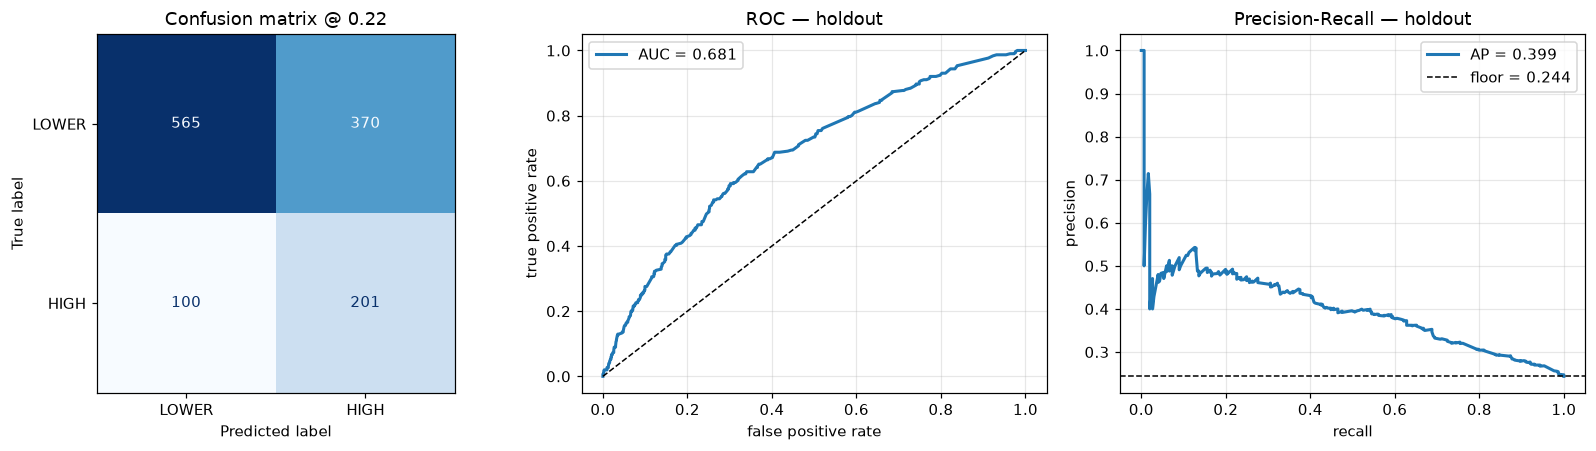

Of 301 genuinely high-acuity patients, 201 are flagged and 100 missed.
Of 935 lower-acuity patients, 370 are flagged for an unnecessary second look.


In [19]:
hold_data = as_categorical(X_hold) if NEEDS_CATEGORICAL else X_hold
p_hold = final_model.predict_proba(hold_data)[:, 1]
y_pred_hold = (p_hold >= THRESHOLD).astype(int)

holdout_metrics = {
    "ROC_AUC": roc_auc_score(y_hold, p_hold),
    "PR_AUC": average_precision_score(y_hold, p_hold),
    "Brier": brier_score_loss(y_hold, p_hold),
    "recall": recall_score(y_hold, y_pred_hold),
    "precision": precision_score(y_hold, y_pred_hold),
    "specificity": recall_score(y_hold, y_pred_hold, pos_label=0),
    "F2": fbeta_score(y_hold, y_pred_hold, beta=2),
    "alert_rate": float(y_pred_hold.mean()),
}

print("=" * 58)
print("HELD-OUT RESULTS (first and only reading)")
print("=" * 58)
print(f"  PR-AUC      {holdout_metrics['PR_AUC']:.3f}   (floor = {y_hold.mean():.3f})")
print(f"  ROC-AUC     {holdout_metrics['ROC_AUC']:.3f}")
print(f"  Brier       {holdout_metrics['Brier']:.3f}")
print(f"\n  At threshold {THRESHOLD:.2f}:")
for k in ["recall", "precision", "specificity", "F2", "alert_rate"]:
    print(f"  {k:12s}{holdout_metrics[k]:.3f}")
print()
print(classification_report(y_hold, y_pred_hold,
                            target_names=["LOWER acuity", "HIGH acuity"], digits=3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
cm = confusion_matrix(y_hold, y_pred_hold)
ConfusionMatrixDisplay(cm, display_labels=["LOWER", "HIGH"]).plot(
    ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set(title=f"Confusion matrix @ {THRESHOLD:.2f}"); axes[0].grid(False)
fpr, tpr, _ = roc_curve(y_hold, p_hold)
axes[1].plot(fpr, tpr, lw=2, label=f"AUC = {holdout_metrics['ROC_AUC']:.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC — holdout")
axes[1].legend()
prec, rec, _ = precision_recall_curve(y_hold, p_hold)
axes[2].plot(rec, prec, lw=2, label=f"AP = {holdout_metrics['PR_AUC']:.3f}")
axes[2].axhline(y_hold.mean(), color="k", ls="--", lw=1, label=f"floor = {y_hold.mean():.3f}")
axes[2].set(xlabel="recall", ylabel="precision", title="Precision-Recall — holdout")
axes[2].legend()
plt.tight_layout(); plt.savefig(ARTIFACTS / "holdout_evaluation.png", bbox_inches="tight"); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"Of {tp + fn} genuinely high-acuity patients, {tp} are flagged and {fn} missed.")
print(f"Of {tn + fp} lower-acuity patients, {fp} are flagged for an unnecessary second look.")

## 18. The nurse-facing interface

`predict_severity()` takes **raw arrival fields only** and runs the same `engineer_features()`
used in training — no second copy to drift.

| Result | Meaning |
|---|---|
| `HIGH` | Escalation likely; prioritise |
| `LOW` | Escalation unlikely |
| `BORDERLINE` | No reliable call; nurse's own assessment stands |
| `DEFER TO CLINICAL JUDGEMENT` | Below the completeness floor |

Plain field names, probability anchored to the average arrival, and occlusion-based reasons
filtered to the verdict direction.

In [20]:
perm = permutation_importance(final_model, hold_data, y_hold, scoring="average_precision",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = (pd.DataFrame({"feature": X_hold.columns, "importance": perm.importances_mean,
                            "std": perm.importances_std})
              .sort_values("importance", ascending=False).reset_index(drop=True))
print(importance.to_string(index=False, float_format="%.4f"))

plt.figure(figsize=(8, max(4, 0.34 * len(importance))))
top = importance.iloc[::-1]
plt.barh(top["feature"], top["importance"], xerr=top["std"], color="#2c5f8d", alpha=0.85)
plt.axvline(0, color="k", lw=1)
plt.xlabel("drop in PR-AUC when shuffled"); plt.title("Permutation importance (holdout)")
plt.tight_layout(); plt.savefig(ARTIFACTS / "permutation_importance.png", bbox_inches="tight")
plt.show()

BrokenProcessPool: A task has failed to un-serialize. Please ensure that the arguments of the function are all picklable.

### Distribution on the holdout

Zones were fixed on validation; checks whether they transfer to unseen data.

In [ ]:
NURSE_LABELS = {
    "Age": "age",
    "Time of Collision": "time of accident",
    "Mode Of Travel During Accident": "how they were travelling",
    "Collision With ": "what they collided with",
    "Mode of Transport to the Hospital": "how they reached hospital",
    "Time Taken To Reach Hospital": "time taken to reach hospital",
    "Site of Injury No1": "main injury site",
    "Site of injury No 2": "second injury site",
    "Vehicle Type": "vehicle type",
    "Helmet Worn": "helmet worn",
    "Passenger Type": "passenger type",
    "Other Injury": "other injury",
}

AVERAGE_ARRIVAL = float(y_val.mean())


def score(record):
    raw = pd.DataFrame([{f: record.get(f) for f in RAW_INPUTS}])
    row = apply_ordinal_encoding(engineer_features(raw))[FEATURES]
    for c in CAT_FEATURES:
        row[c] = row[c].astype("category") if NEEDS_CATEGORICAL else row[c].astype(object)
    return float(final_model.predict_proba(row)[0, 1])


def classify_zone(prob):
    if prob >= HIGH_CUT:
        return "HIGH", "escalation likely - prioritise this patient"
    if prob < LOW_CUT:
        return "LOW", "escalation unlikely - safe to deprioritise"
    return "BORDERLINE", (f"close to the average arrival ({AVERAGE_ARRIVAL:.0%}), so this does "
                          "not shift your own assessment either way")


def explain(record, prob, verdict, top_n=3):
    """Hide each detail in turn; keep those that pushed toward the verdict."""
    shifts = []
    for f in RAW_INPUTS:
        if record.get(f) is None or pd.isna(record.get(f)):
            continue
        without = dict(record)
        without[f] = None
        shifts.append((f, prob - score(without)))

    if verdict == "HIGH":
        aligned = [(f, d) for f, d in shifts if d > 0.01]
    elif verdict == "LOW":
        aligned = [(f, d) for f, d in shifts if d < -0.01]
    else:
        aligned = [(f, d) for f, d in shifts if abs(d) > 0.01]
    aligned.sort(key=lambda kv: abs(kv[1]), reverse=True)

    reasons = [f"{NURSE_LABELS.get(f, f)} ({record[f]}) "
               f"{'raised' if d > 0 else 'lowered'} the estimate" for f, d in aligned[:top_n]]
    if not reasons:
        reasons.append("no single detail drove this - it comes from the combination of details")
    return reasons


def predict_severity(record: dict) -> dict:
    """Triage prediction from raw arrival-time fields. Unknown fields may be omitted."""
    present = sum(1 for f in RAW_INPUTS
                  if record.get(f) is not None and not pd.isna(record.get(f)))
    completeness = present / len(RAW_INPUTS)
    missing = [NURSE_LABELS.get(f, f) for f in RAW_INPUTS
               if record.get(f) is None or pd.isna(record.get(f))]

    if completeness < COMPLETENESS_FLOOR:
        return {"result": "DEFER TO CLINICAL JUDGEMENT", "probability": None,
                "completeness": round(completeness, 3), "reasons": [],
                "missing_fields": missing,
                "message": f"Only {present} of {len(RAW_INPUTS)} details recorded. "
                           f"Add {', '.join(missing[:3])} to get an estimate."}

    prob = score(record)
    result, note = classify_zone(prob)
    return {"result": result, "probability": round(prob, 3),
            "completeness": round(completeness, 3),
            "reasons": explain(record, prob, result), "missing_fields": missing,
            "message": f"{result} ({prob:.0%} chance of needing escalated care; "
                       f"average arrival is {AVERAGE_ARRIVAL:.0%}) - {note}."}


def ask(record):
    out = predict_severity(record)
    print(out["message"])
    for r in out["reasons"]:
        print(f"   - {r}")
    if out["missing_fields"]:
        print(f"   (not recorded: {', '.join(out['missing_fields'])})")
    print()


print(f"The nurse supplies {len(RAW_INPUTS)} details:")
for f in RAW_INPUTS:
    print(f"   - {NURSE_LABELS.get(f, f)}")
print()
for idx in range(6):
    ask({f: df.loc[X_hold.index[idx], f] for f in RAW_INPUTS})
print("Partially completed record:")
ask({f: df.loc[X_hold.index[0], f] for f in RAW_INPUTS[:4]})
print("Almost nothing recorded:")
ask({RAW_INPUTS[0]: df.loc[X_hold.index[0], RAW_INPUTS[0]]})

The nurse supplies 12 details:
   - time of accident
   - age
   - how they were travelling
   - what they collided with
   - vehicle type
   - helmet worn
   - passenger type
   - how they reached hospital
   - time taken to reach hospital
   - main injury site
   - second injury site
   - other injury

HIGH (36% chance of needing escalated care; average arrival is 24%) - escalation likely - prioritise this patient.
   - main injury site (cervical) raised the estimate
   - time of accident (09:00 - 12:00) raised the estimate
   - age (40-49) raised the estimate
   (not recorded: vehicle type, helmet worn, passenger type, other injury)

BORDERLINE (16% chance of needing escalated care; average arrival is 24%) - close to the average arrival (24%), so this does not shift your own assessment either way.
   - time of accident (15:00 - 18:00) lowered the estimate
   - second injury site (no secondary injury found) raised the estimate
   - main injury site (forehead) raised the estimate
   (

## 19. Save artifacts

            patients share severity_rate
zone                                    
BORDERLINE       857 69.3%         19.5%
DEFER             21  1.7%         14.3%
HIGH             309 25.0%         41.1%
LOW               49  4.0%          8.2%

Average arrival severity: 24.4%

Severity among deferred: 14.3% vs 24.5% among answered
A lower rate among deferred records means the model is not going quiet exactly
when it is needed most.


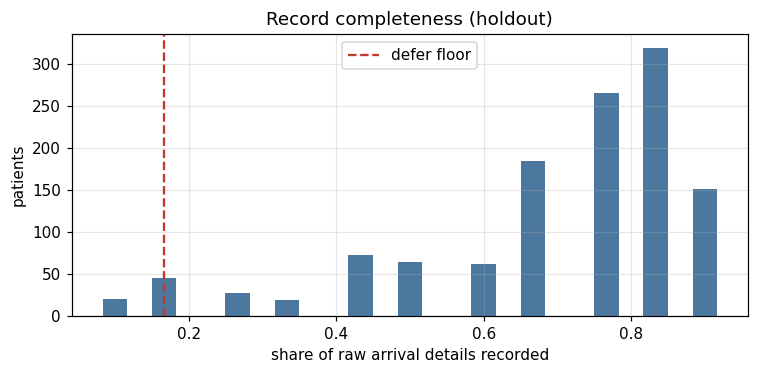

In [ ]:
raw_hold = df.loc[X_hold.index, RAW_INPUTS]
completeness_hold = raw_hold.notna().sum(axis=1) / len(RAW_INPUTS)
defer_hold = (completeness_hold < COMPLETENESS_FLOOR).values

zone_hold = np.where(p_hold >= HIGH_CUT, "HIGH",
                     np.where(p_hold < LOW_CUT, "LOW", "BORDERLINE"))
zone_hold = np.where(defer_hold, "DEFER", zone_hold)

zone_table = (pd.DataFrame({"zone": zone_hold, "severe": y_hold.values})
              .groupby("zone")
              .agg(patients=("severe", "size"),
                   share=("severe", lambda s: len(s) / len(y_hold)),
                   severity_rate=("severe", "mean")))
print(zone_table.to_string(formatters={"share": "{:.1%}".format,
                                       "severity_rate": "{:.1%}".format}))
print(f"\nAverage arrival severity: {y_hold.mean():.1%}")

if defer_hold.any() and (~defer_hold).any():
    print(f"\nSeverity among deferred: {y_hold[defer_hold].mean():.1%} "
          f"vs {y_hold[~defer_hold].mean():.1%} among answered")
    print("A lower rate among deferred records means the model is not going quiet exactly")
    print("when it is needed most.")

plt.figure(figsize=(7, 3.5))
plt.hist(completeness_hold, bins=25, color="#2c5f8d", alpha=0.85)
plt.axvline(COMPLETENESS_FLOOR, color="#c0392b", ls="--", lw=1.5, label="defer floor")
plt.xlabel("share of raw arrival details recorded"); plt.ylabel("patients")
plt.title("Record completeness (holdout)"); plt.legend()
plt.tight_layout(); plt.savefig(ARTIFACTS / "completeness.png", bbox_inches="tight"); plt.show()

## 19. Save artifacts

In [ ]:
import joblib

joblib.dump({"model": final_model, "features": FEATURES, "cat_features": CAT_FEATURES,
             "num_features": NUM_FEATURES, "raw_inputs": RAW_INPUTS,
             "ordinal_orders": ORDINAL_ORDERS, "engineered_sources": ENGINEERED_SOURCES,
             "threshold": THRESHOLD, "low_cut": LOW_CUT, "high_cut": HIGH_CUT,
             "completeness_floor": COMPLETENESS_FLOOR,
             "needs_categorical": NEEDS_CATEGORICAL},
            ARTIFACTS / "severity_triage_model.joblib")

summary = {
    "purpose": "Arrival-time triage support: flags road-accident patients likely to need "
               "escalated care (transfer, major procedure, or further interventions).",
    "split": {"train": len(y_train), "validation": len(y_val), "holdout": len(y_hold),
              "protocol": "all decisions on train/validation; holdout read once"},
    "target": {"rule": "further interventions OR transferred out OR major procedure",
               "prevalence": round(float(df["severity_high"].mean()), 4),
               "excluded_from_label": "length of stay (confounded by transfer-out)"},
    "leakage_audit": audit.value_counts().to_dict(),
    "features": {"candidates": len(CANDIDATES), "selection_rule": winner,
                 "final": FEATURES, "dropped": DROPPED,
                 "raw_fields_nurse_supplies": RAW_INPUTS},
    "model": {"family": BEST_MODEL,
              "best_params": {k: str(v) for k, v in search.best_params_.items()},
              "calibrated": bool(USE_CALIBRATION)},
    "decisions": {"miss_cost_ratio": MISS_COST_RATIO, "threshold": round(THRESHOLD, 3),
                  "low_cut": round(LOW_CUT, 3), "high_cut": round(HIGH_CUT, 3),
                  "completeness_floor": round(COMPLETENESS_FLOOR, 3)},
    "holdout_metrics": {k: round(float(v), 4) for k, v in holdout_metrics.items()},
    "holdout_zone_distribution": zone_table["share"].round(4).to_dict(),
    "holdout_zone_severity": zone_table["severity_rate"].round(4).to_dict(),
    "top_features": importance.head(8)["feature"].tolist(),
}
with open(ARTIFACTS / "model_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

screening.to_csv(ARTIFACTS / "feature_screening.csv", index=False)
importance.to_csv(ARTIFACTS / "permutation_importance.csv", index=False)
results.to_csv(ARTIFACTS / "model_comparison.csv", index=False)

print(json.dumps(summary, indent=2))
print(f"\nSaved to {ARTIFACTS.resolve()}")

{
  "purpose": "Arrival-time triage support: flags road-accident patients likely to need escalated care (transfer, major procedure, or further interventions).",
  "split": {
    "train": 3706,
    "validation": 1236,
    "holdout": 1236,
    "protocol": "all decisions on train/validation; holdout read once"
  },
  "target": {
    "rule": "further interventions OR transferred out OR major procedure",
    "prevalence": 0.2436,
    "excluded_from_label": "length of stay (confounded by transfer-out)"
  },
  "leakage_audit": {
    "BOOKKEEPING": 65,
    "EXCLUDED_ETHICAL": 16,
    "TARGET_INPUT": 14,
    "ARRIVAL": 12,
    "SCENE_OR_TEST_DEPENDENT": 10,
    "POST_ARRIVAL": 9,
    "ADMIN": 4
  },
  "features": {
    "candidates": 20,
    "selection_rule": "all candidates",
    "final": [
      "Time of Collision",
      "Age",
      "Mode Of Travel During Accident",
      "Collision With ",
      "Vehicle Type",
      "Helmet Worn",
      "Passenger Type",
      "Mode of Transport to the Hos

## 20. Limitations

**1. Moderate discrimination.** Holdout ROC-AUC ~0.68; five model families converge there —
reflects arrival-time data's information content, not a tuning failure. A **screening aid**, not
a diagnostic instrument.

**2. Large BORDERLINE share.** Zones meet stated reliability requirements; anything that can't is
left undecided.

**3. The label is a hospital decision, not injury severity.** Bed availability and staffing
confound it.

**4. Three stated clinical choices remain.** `MISS_COST_RATIO` (5), `LOW_ZONE_MAX_SEVERITY`
(0.10), `HIGH_ZONE_MIN_SEVERITY` (0.45) — judgements, not findings.

**5. Partial circularity in injury-type validation.** Fracture stabilisation counts as major, so
fracture patients favour HIGH by construction.

**6. Explanations are faithful to the model, not clinical causation.**

**7. Heavy, non-random missingness**, handled rather than imputed away.

**8. Single-setting data** — one hospital network, northern Sri Lanka.

**9. Not validated prospectively.**

---

The headline metric reflects what a nurse genuinely has at arrival, not what merely correlates
with the outcome in hindsight — a harder and narrower question, and the one actually being
asked.